# 02 - Is the real code better than random codes?

I make 100,000 fake genetic codes and give each one the same score as in notebook 01.

To make a fake code I keep the groups of codons the same (e.g. the 4 `GC_` codons still mean one amino acid, the stop codons stay stop) but shuffle **which** amino acid each group means. That way the only difference is which amino acids end up next to each other.

I also score 3 other properties to see if the code is special for everything or only some things:
- **hydropathy** (Kyte & Doolittle 1982): another "likes water" scale
- **molecular weight**
- **alphabetical order** of the amino acid letter: a control that shouldn't matter at all

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from geneticcode import AMINO_ACIDS, GENETIC_CODE, error_cost, load_properties, random_code

props = load_properties()
properties = {
    "polar requirement": props["polar_requirement"].to_dict(),
    "hydropathy": props["hydropathy"].to_dict(),
    "molecular weight": props["molecular_weight"].to_dict(),
    "alphabetical (control)": {aa: i for i, aa in enumerate(AMINO_ACIDS)},
}

real_scores = {}
for name, values in properties.items():
    real_scores[name] = error_cost(GENETIC_CODE, values)
real_scores

{'polar requirement': np.float64(5.193574144486692),
 'hydropathy': np.float64(9.393954372623577),
 'molecular weight': np.float64(1180.1061946768061),
 'alphabetical (control)': np.float64(52.555133079847906)}

This takes about a minute (100,000 codes x 4 properties).

In [2]:
np.random.seed(42)  # so I get the same random codes every time
N = 100_000

fake_scores = {name: [] for name in properties}
for i in range(N):
    fake = random_code()
    for name, values in properties.items():
        fake_scores[name].append(error_cost(fake, values))

# turn the lists into numpy arrays so I can compare them all at once
for name in properties:
    fake_scores[name] = np.array(fake_scores[name])

In [3]:
for name in properties:
    scores = fake_scores[name]
    better = np.sum(scores < real_scores[name])  # True counts as 1
    print(f"{name:25s} real = {real_scores[name]:8.2f}   "
          f"fake average = {np.mean(scores):8.2f}   "
          f"fake codes better: {better:6d}  ({100 * better / N:.3f}%)")

polar requirement         real =     5.19   fake average =     9.41   fake codes better:     10  (0.010%)
hydropathy                real =     9.39   fake average =    13.30   fake codes better:    800  (0.800%)
molecular weight          real =  1180.11   fake average =  1419.91   fake codes better:  15563  (15.563%)
alphabetical (control)    real =    52.56   fake average =    52.15   fake codes better:  53398  (53.398%)


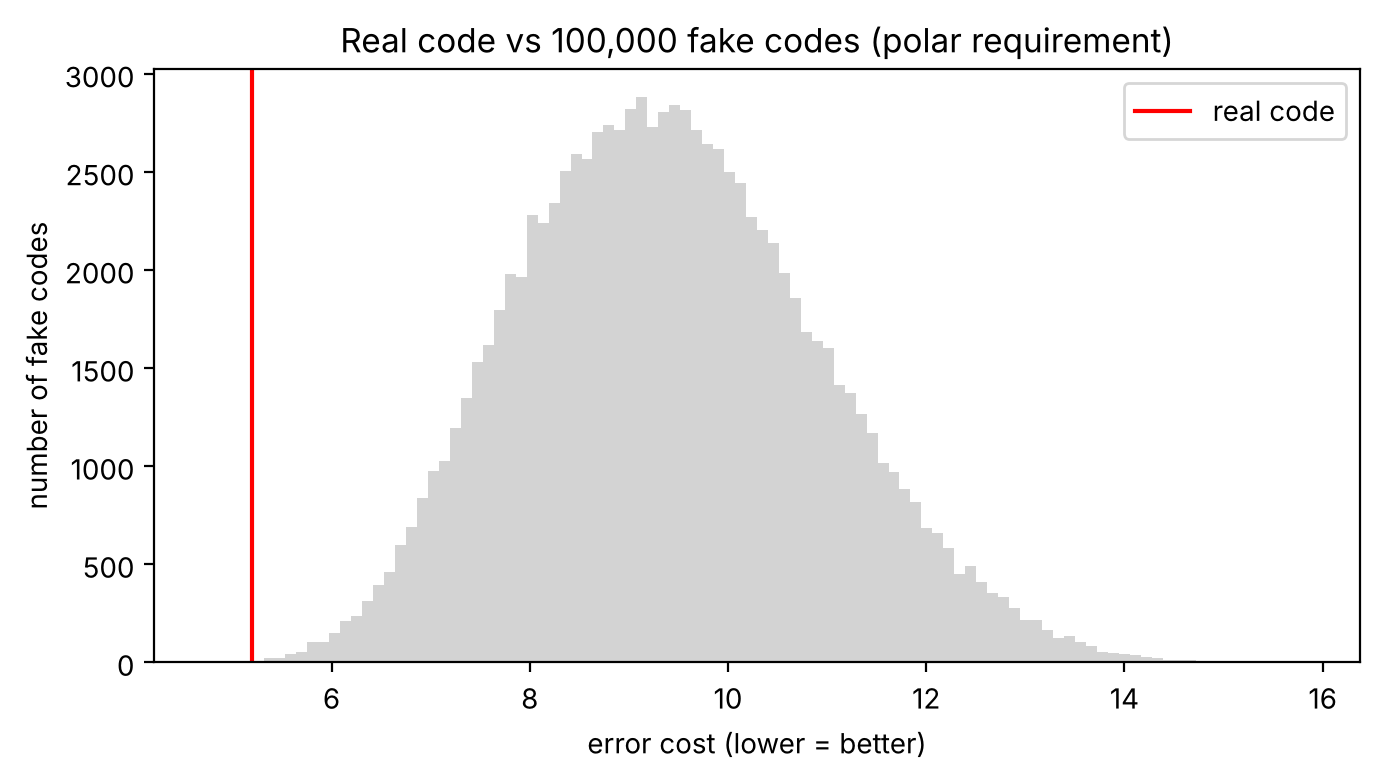

In [4]:
plt.figure(figsize=(7, 4))
plt.hist(fake_scores["polar requirement"], bins=100, color="lightgray")
plt.axvline(real_scores["polar requirement"], color="red", label="real code")
plt.xlabel("error cost (lower = better)")
plt.ylabel("number of fake codes")
plt.title("Real code vs 100,000 fake codes (polar requirement)")
plt.legend()
plt.tight_layout()
plt.savefig("figures/02_fake_codes.png", dpi=120)
plt.show()

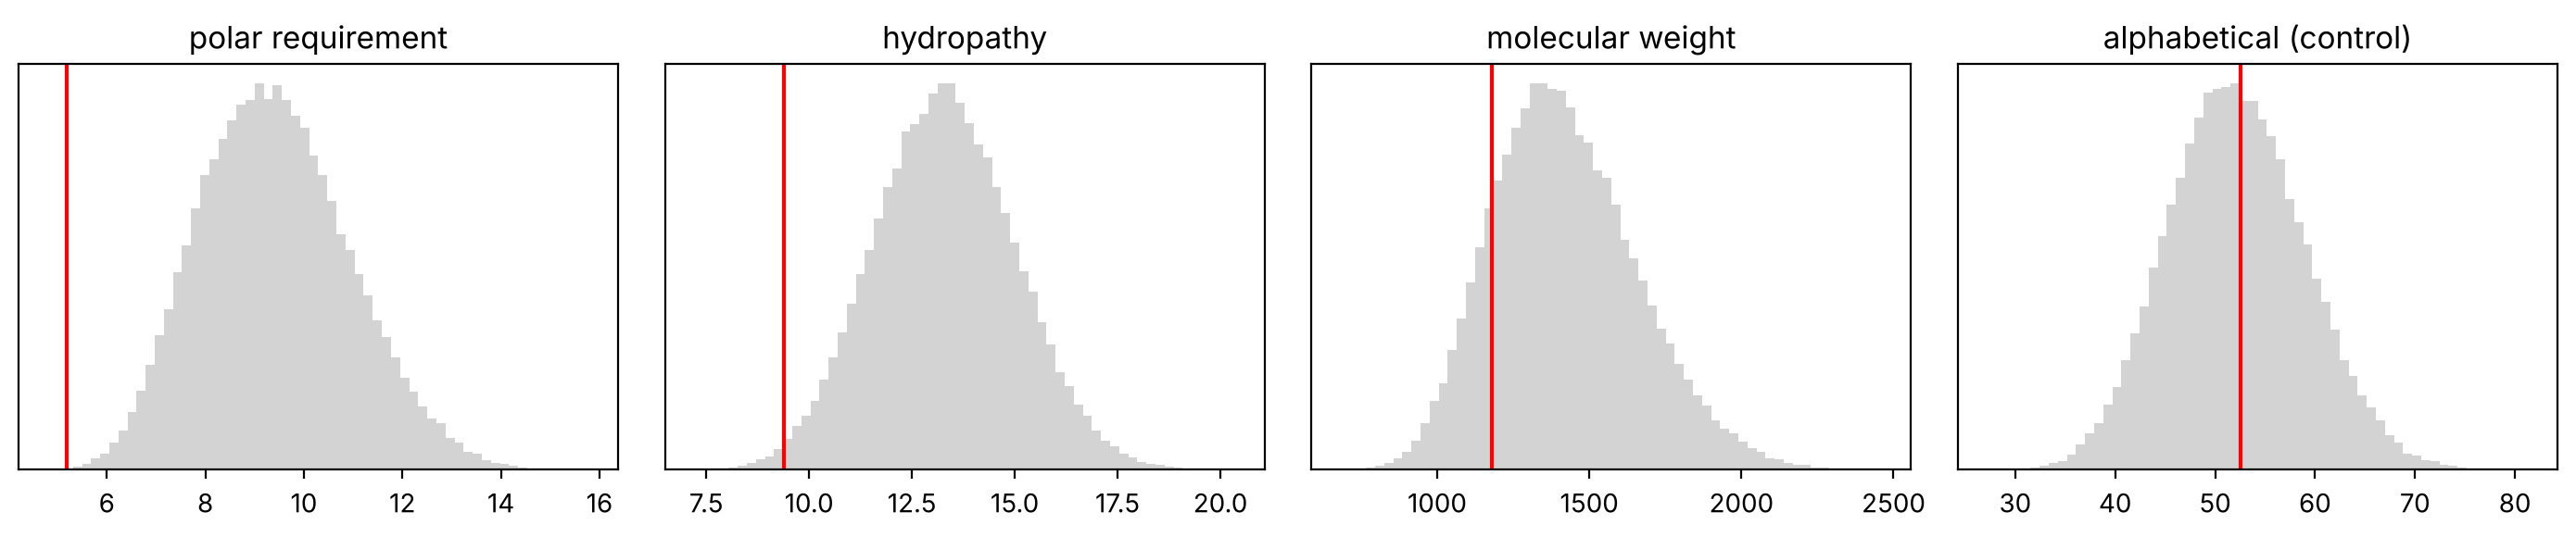

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, name in zip(axes, properties):
    ax.hist(fake_scores[name], bins=60, color="lightgray")
    ax.axvline(real_scores[name], color="red")
    ax.set_title(name)
    ax.set_yticks([])
plt.tight_layout()
plt.savefig("figures/03_four_properties.png", dpi=120)
plt.show()

## What I found

- **Polar requirement:** only 10 out of 100,000 fake codes beat the real one (1 in 10,000). That's the same as Haig & Hurst (1991) found.
- **Hydropathy:** under 1%, still good.
- **Molecular weight:** about 15% of fake codes are better, so nothing special.
- **Alphabetical control:** about 53%, right in the middle, which is what should happen for something meaningless. So my method isn't biased towards the real code.

So the code isn't the best at everything. It's mostly good at keeping an amino acid's **relationship with water** the same after a mutation. That makes sense because whether an amino acid likes water decides whether it goes inside or outside a folded protein.

This doesn't prove *why* the code is like this. It could be natural selection, or the code could have grown by giving new codons to similar amino acids.